In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
data_1 = pd.read_parquet('train-00000-of-00003')
data_2 = pd.read_parquet('train-00001-of-00003')
data_3 = pd.read_parquet('train-00002-of-00003')


"\ndata_1 = pd.read_parquet('train-00000-of-00003')\ndata_2 = pd.read_parquet('train-00001-of-00003')\ndata_3 = pd.read_parquet('train-00002-of-00003')\n"

In [ ]:
data_1.describe()

,label,text
count,369101,369101
unique,21,364674
top,legaladvice,What do you call a cheap circumcision? A rip off
freq,112013,5


In [ ]:
data_2.describe()

,label,text
count,369101,369101
unique,23,360708
top,depression,"[Utah] For those who are shy, anxious, and/or ..."
freq,71587,4


In [ ]:
data_3.describe()

,label,text
count,369100,369100
unique,25,357057
top,jokes,"A Reddit user, a Reddit user, and a Reddit use..."
freq,46249,8


In [ ]:
print(data_1.head(5))
print(data_2.head(5))
print(data_3.head(5))

       label                                               text
0  addiction  Deciding to go of tramadol Well after never ta...
1  addiction  My vyvanse addiction... It has gotten pretty b...
2  addiction  Quitting coke and nicotine I'm gonna start by ...
3  addiction  Is it OK to leave a drug addict you love?  Man...
4  addiction  My brother has a problem I'm not against weed....
             label                                               text
0  personalfinance  Apple/Google Pay; AmEx cashback question I am ...
1  personalfinance  23, First Job, Looking for Budget C&amp;C and ...
2  personalfinance  Am I still able to collect unemployment benefi...
3  personalfinance  Do I have to pay the healthcare penalty if I w...
4  personalfinance  Financial issue - could use starting point? (M...
          label                                               text
0  mentalhealth  "Clicking" with your therapist? How long shoul...
1  mentalhealth  I don’t know what to love for anymore I’ve be

In [ ]:
df = pd.concat([data_1, data_2, data_3], ignore_index=True)

In [ ]:
df.head()

,label,text
0,addiction,Deciding to go of tramadol Well after never ta...
1,addiction,My vyvanse addiction... It has gotten pretty b...
2,addiction,Quitting coke and nicotine I'm gonna start by ...
3,addiction,Is it OK to leave a drug addict you love? Man...
4,addiction,My brother has a problem I'm not against weed....


In [ ]:
df['label'].unique()

array(['addiction', 'bipolarreddit', 'teaching', 'autism',
       'healthanxiety', 'bpd', 'depression', 'relationships', 'guns',
       'meditation', 'jokes', 'alcoholism', 'COVID19_support',
       'personalfinance', 'legaladvice', 'adhd', 'divorce', 'anxiety',
       'conspiracy', 'lonely', 'schizophrenia', 'parenting',
       'socialanxiety', 'suicidewatch', 'ptsd', 'mentalhealth', 'fitness',
       'EDAnonymous'], dtype=object)

In [ ]:
df['label'] = df['label'].replace({
    'anxiety': 'anxiety_merged',
    'socialanxiety': 'anxiety_merged',
    'healthanxiety': 'anxiety_merged'
})

In [ ]:
df['label'] = df['label'].replace({
    'alcoholism': 'addiction_merged',
    'addiction': 'addiction_merged',
})

In [ ]:
df['label'].unique()

array(['addiction_merged', 'bipolarreddit', 'teaching', 'autism',
       'anxiety_merged', 'bpd', 'depression', 'relationships', 'guns',
       'meditation', 'jokes', 'COVID19_support', 'personalfinance',
       'legaladvice', 'adhd', 'divorce', 'conspiracy', 'lonely',
       'schizophrenia', 'parenting', 'suicidewatch', 'ptsd',
       'mentalhealth', 'fitness', 'EDAnonymous'], dtype=object)

In [ ]:
labels = ['bipolarreddit', 'bpd', 'depression', 'schizophrenia', 'autism', 'adhd', 'ptsd', 'suicidewatch']
df_new = df[df['label'].isin(labels)].drop_duplicates(subset='text').copy()

In [ ]:
df_new['label'].unique()

array(['bipolarreddit', 'autism', 'bpd', 'depression', 'adhd',
       'schizophrenia', 'suicidewatch', 'ptsd'], dtype=object)

In [ ]:
df_new.info()

<class 'pandas.core.frame.DataFrame'>
Index: 285421 entries, 502 to 331139
Data columns (total 2 columns):
 #   Column  Non-Null Count   Dtype 
---  ------  --------------   ----- 
 0   label   285421 non-null  object
 1   text    285421 non-null  object
dtypes: object(2)
memory usage: 6.5+ MB


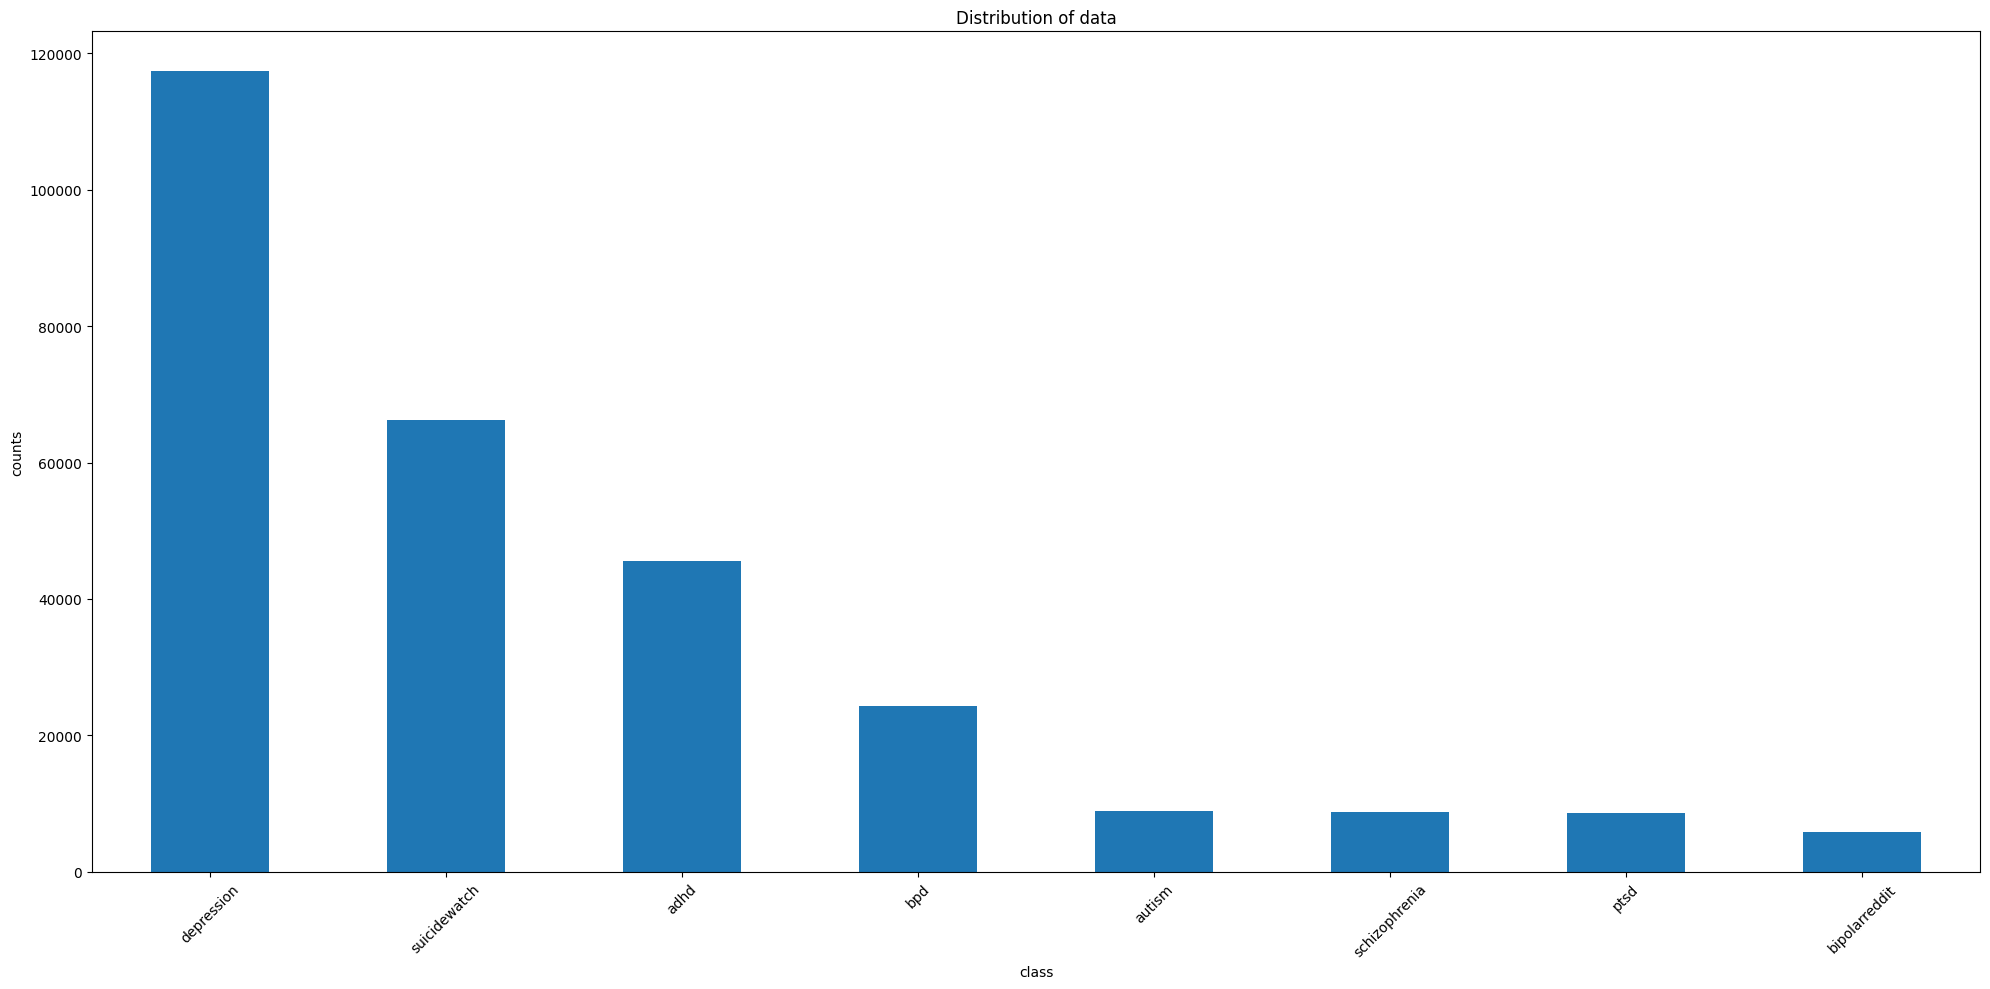

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(20,10))
label_counts = df_new['label'].value_counts()
label_counts.plot(kind='bar')
plt.ylabel('counts')
plt.xticks(rotation=45)
plt.xlabel('class')
plt.title('Distribution of data')
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import StratifiedShuffleSplit
splitter = StratifiedShuffleSplit(test_size=0.2, n_splits=1, random_state=42)
X = df_new['text']
y = df_new['label']
for train_val_ix, test_ix in splitter.split(X, y):
  X_train_val, X_test = X.iloc[train_val_ix], X.iloc[test_ix]
  y_train_val, y_test = y.iloc[train_val_ix], y.iloc[test_ix]

In [ ]:
splitter_2 = StratifiedShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
for train_ix, val_ix in splitter_2.split(X_train_val, y_train_val):
  X_train, X_val = X_train_val.iloc[train_ix], X_train_val.iloc[val_ix]
  y_train, y_val = y_train_val.iloc[train_ix], y_train_val.iloc[val_ix]

sanity checks

In [ ]:
print(len(X_train)/len(X))

0.599997897842135


In [ ]:
print(len(X_val)/len(X))

0.19999929928071164


In [ ]:
print(len(X_test)/len(X))

0.20000280287715339


In [ ]:
from transformers import AutoTokenizer, BertForSequenceClassification
import torch
tokenizer = AutoTokenizer.from_pretrained("google-bert/bert-base-cased")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/436k [00:00<?, ?B/s]

In [ ]:
num_labels = len(df_new['label'].unique())
print(f"number of labels {num_labels}")
model = BertForSequenceClassification.from_pretrained('google-bert/bert-base-cased',
                                                      num_labels=num_labels)

number of labels 8


Loading weights:   0%|          | 0/206 [00:00<?, ?it/s]

In [ ]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)
y_test_encoded = le.transform(y_test)
y_val_encoded = le.transform(y_val)
for i, label in enumerate(le.classes_):
    print(f"{label} → {i}")

adhd → 0
autism → 1
bipolarreddit → 2
bpd → 3
depression → 4
ptsd → 5
schizophrenia → 6
suicidewatch → 7


In [ ]:
X_train_encodings = tokenizer(
    X_train.tolist(),
    max_length=512,
    truncation=True
)

In [ ]:
X_test_encodings = tokenizer(
    X_test.tolist(),
    max_length=512,
    truncation=True
)

In [ ]:
X_val_encodings = tokenizer(
    X_val.tolist(),
    max_length=512,
    truncation=True
)

In [ ]:
class RedditDataset(torch.utils.data.Dataset):
  def __init__(self, encodings, labels):
    self.encodings = encodings
    self.labels = labels

  def __getitem__(self, idx):
    item = {key: val[idx] for key, val in self.encodings.items()}
    item['labels'] = int(self.labels[idx])
    return item

  def __len__(self):
    return len(self.labels)

train_dataset = RedditDataset(X_train_encodings, y_train_encoded)
val_dataset = RedditDataset(X_val_encodings, y_val_encoded)
test_dataset = RedditDataset(X_test_encodings, y_test_encoded)

In [ ]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)

def compute_metrics(eval_pred):
  logits, labels = eval_pred
  preds = np.argmax(logits, axis=1)
  return {
      'accuracy': accuracy_score(labels, preds),
      'f1_macro': f1_score(labels, preds, average='macro'),
      'f1_weighted': f1_score(labels, preds, average='weighted')
  }

In [ ]:
from transformers import TrainingArguments, Trainer, DataCollatorWithPadding

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

training_args = TrainingArguments(
    output_dir='bert_results',
    num_train_epochs=2,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    learning_rate=2e-5,
    weight_decay=0.01,
    warmup_steps=500,
    eval_strategy='epoch',
    save_strategy='epoch',
    load_best_model_at_end=True,
    metric_for_best_model='f1_macro',
    save_total_limit=1,
    logging_steps=500,
    fp16=torch.cuda.is_available(),
    report_to='none'
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

In [ ]:
trainer.train()

In [ ]:
test_output = trainer.predict(test_dataset)
test_logits = test_output.predictions
y_true = test_output.label_ids
y_pred = np.argmax(test_logits, axis=1)
probs = torch.softmax(torch.tensor(test_logits), dim=1).numpy()

In [ ]:
print(f"accuracy:            {accuracy_score(y_true, y_pred):.4f}")
print(f"precision (macro):   {precision_score(y_true, y_pred, average='macro'):.4f}")
print(f"recall (macro):      {recall_score(y_true, y_pred, average='macro'):.4f}")
print(f"f1 (macro):          {f1_score(y_true, y_pred, average='macro'):.4f}")
print(f"f1 (weighted):       {f1_score(y_true, y_pred, average='weighted'):.4f}")
print(f"roc auc (macro, ovr): {roc_auc_score(y_true, probs, multi_class='ovr', average='macro'):.4f}")
print()
print(classification_report(y_true, y_pred, target_names=le.classes_, digits=4))

In [ ]:
cm = confusion_matrix(y_true, y_pred)
cm_norm = confusion_matrix(y_true, y_pred, normalize='true')

fig, ax = plt.subplots(1, 2, figsize=(22, 9))
ConfusionMatrixDisplay(cm, display_labels=le.classes_).plot(ax=ax[0], cmap='Blues', xticks_rotation=45, values_format='d')
ax[0].set_title('Confusion matrix (counts)')
ConfusionMatrixDisplay(cm_norm, display_labels=le.classes_).plot(ax=ax[1], cmap='Blues', xticks_rotation=45, values_format='.2f')
ax[1].set_title('Confusion matrix (normalised by true class)')
plt.tight_layout()
plt.show()

In [ ]:
off_diag = cm.copy()
np.fill_diagonal(off_diag, 0)
confused = pd.DataFrame(off_diag, index=le.classes_, columns=le.classes_).stack()
confused.index.names = ['true', 'predicted']
confused.sort_values(ascending=False).head(10)

In [ ]:
results = pd.DataFrame({
    'text': X_test.values,
    'true_label': le.inverse_transform(y_true),
    'predicted_label': le.inverse_transform(y_pred),
    'confidence': probs.max(axis=1)
})
errors = results[results['true_label'] != results['predicted_label']]
errors = errors.sort_values('confidence', ascending=False)
errors.to_csv('misclassified.csv', index=False)
print(f"{len(errors)} of {len(results)} test posts misclassified, saved to misclassified.csv")